# FireLens — Exploratory Data Analysis & Sensor Harmonization
### NASA Space Apps Challenge 2026: Harmonization of MODIS and VIIRS Hot Spots

---

## 1. Executive Summary & Scientific Purpose

### 1.1 Context & Scientific Challenge
Satellite-based active fire monitoring is the global backbone of wildfire response, emissions modeling, and climate disturbance tracking. For over two decades, the **Moderate Resolution Imaging Spectroradiometer (MODIS)** aboard NASA's Terra and Aqua satellites has provided a benchmark fire record. In recent years, the **Visible Infrared Imaging Radiometer Suite (VIIRS)** on Suomi-NPP, NOAA-20, and NOAA-21 has ushered in a new era with 375-meter spatial resolution and enhanced fire detection sensitivity.

However, direct comparison and combined use of MODIS and VIIRS present profound scientific hurdles:
1. **Resolution Mismatch:** MODIS detects fires at 1,000-meter nadir resolution (expanding to ~5,000 m at scan edge), while VIIRS I-band operates at 375 meters (expanding only to ~800 m).
2. **Detection Sensitivity:** VIIRS resolves fires as small as ~0.5–1.0 MW Fire Radiative Power (FRP), while MODIS generally detects fires starting at ~8–10 MW.
3. **Footprint Distortion:** VIIRS employs onboard 3:1 and 2:1 pixel aggregation that curbs the geometric "bow-tie" effect, whereas MODIS footprints expand up to 10-fold at scan edges.
4. **Orbital Timing:** Terra, Aqua, and NOAA-20 cross the equator at different local solar times (10:30, 13:30, 13:30), sampling different phases of the diurnal fire curve.

### 1.2 Objective of this Scientific Study
This notebook conducts a rigorous, multi-sensor exploratory data analysis (EDA) across **22,175,341 authentic NASA FIRMS observations** from the full 2025 calendar year:
- **MODIS C6.1:** 3,708,772 observations (Terra & Aqua)
- **VIIRS C2:** 18,466,569 observations (NOAA-20 / JPSS-1)

The objective is to establish the empirical distributions, quantify multi-sensor discrepancies, evaluate spatial-temporal dynamics, and formulate concrete rules for the Phase 4 Harmonization Engine.

---
## 2. Dataset Overview, Environment Setup & Schema Inspection

We initialize our analytical environment using high-performance vectorized libraries (`DuckDB`, `Pandas`, `NumPy`, `Matplotlib`, `Seaborn`). DuckDB serves as our columnar analytic engine to query the 22.17M-record unified catalog with zero memory overhead.

In [1]:
import os
import sys
import time
import json
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style and plotting configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 11
plt.rcParams['figure.titlesize'] = 16

# Paths - robust detection whether running from root or notebooks/ dir
if Path("data/processed/unified_observations.csv").exists():
    BASE_DIR = Path(".").resolve()
elif Path("../data/processed/unified_observations.csv").exists():
    BASE_DIR = Path("..").resolve()
else:
    BASE_DIR = Path(r"d:\user\Documents\nasa").resolve()

DATA_DIR = BASE_DIR / "data"
PROCESSED_FILE = DATA_DIR / "processed" / "unified_observations.csv"
ANALYTICS_DIR = DATA_DIR / "analytics"

print(f"FireLens Base Directory: {BASE_DIR}")
print(f"Unified Observations Path: {PROCESSED_FILE} (Exists: {PROCESSED_FILE.exists()})")
print(f"Analytics Artifacts Path: {ANALYTICS_DIR} (Exists: {ANALYTICS_DIR.exists()})")


FireLens Base Directory: D:\user\Documents\nasa
Unified Observations Path: D:\user\Documents\nasa\data\processed\unified_observations.csv (Exists: True)
Analytics Artifacts Path: D:\user\Documents\nasa\data\analytics (Exists: True)


### 2.1 DuckDB Relational Connection & Schema Discovery
We connect to the unified observations catalog and inspect field representations, data types, and row volume.

In [2]:
con = duckdb.connect()
csv_path = str(PROCESSED_FILE).replace('\\', '/')

# Register unified observations table
query = f'''
    CREATE VIEW unified AS 
    SELECT 
        observation_id,
        latitude,
        longitude,
        acquisition_date,
        acquisition_time,
        timestamp_utc,
        satellite,
        instrument,
        confidence,
        CASE 
            WHEN instrument = 'MODIS' THEN 
                CASE 
                    WHEN TRY_CAST(confidence AS INTEGER) < 30 THEN 'low'
                    WHEN TRY_CAST(confidence AS INTEGER) < 80 THEN 'nominal'
                    ELSE 'high'
                END
            WHEN instrument = 'VIIRS' THEN 
                CASE 
                    WHEN lower(confidence) = 'l' THEN 'low'
                    WHEN lower(confidence) = 'n' THEN 'nominal'
                    WHEN lower(confidence) = 'h' THEN 'high'
                    ELSE 'unknown'
                END
            ELSE 'unknown'
        END AS confidence_category,
        frp,
        brightness,
        daynight,
        CASE WHEN instrument = 'MODIS' THEN 1000 ELSE 375 END as spatial_resolution_m,
        is_valid
    FROM read_csv_auto('{csv_path}', types={{'confidence': 'VARCHAR'}})
'''
con.execute(query)

# Inspect schema and sample
schema_df = con.execute("DESCRIBE unified").df()
display_schema = schema_df[['column_name', 'column_type']]
print("=== Unified Catalog Column Schema ===")
print(display_schema.to_string(index=False))

# Preview first 3 rows
sample_df = con.execute("SELECT observation_id, latitude, longitude, acquisition_date, acquisition_time, instrument, satellite, confidence_category, frp, brightness, daynight FROM unified LIMIT 3").df()
print("\n=== Catalog Data Sample ===")
print(sample_df.to_string(index=False))


=== Unified Catalog Column Schema ===
         column_name              column_type
      observation_id                  VARCHAR
            latitude                   DOUBLE
           longitude                   DOUBLE
    acquisition_date                     DATE
    acquisition_time                     TIME
       timestamp_utc TIMESTAMP WITH TIME ZONE
           satellite                  VARCHAR
          instrument                  VARCHAR
          confidence                  VARCHAR
 confidence_category                  VARCHAR
                 frp                   DOUBLE
          brightness                   DOUBLE
            daynight                  VARCHAR
spatial_resolution_m                  INTEGER
            is_valid                  BOOLEAN



=== Catalog Data Sample ===
 observation_id  latitude  longitude acquisition_date acquisition_time instrument satellite confidence_category  frp  brightness daynight
FL-MOD-00000000   35.0275   136.8820       2025-01-01         00:31:00      MODIS     Terra             nominal 11.2       301.8        D
FL-MOD-00000001   35.9308   140.6772       2025-01-01         00:31:00      MODIS     Terra                 low  6.0       300.6        D
FL-MOD-00000002   35.0292   136.8672       2025-01-01         00:31:00      MODIS     Terra                 low  9.9       300.5        D


---
## 3. Volume & Scale Comparison: The 5x Discrepancy

### 3.1 Observation Count Breakdown
A central finding in multi-sensor fire science is the dramatic disparity in raw detection counts between MODIS and VIIRS over identical temporal periods.

In [3]:
# Compute volume comparison
scale_df = con.execute("""
    SELECT 
        instrument,
        COUNT(*) as total_observations,
        SUM(CASE WHEN is_valid THEN 1 ELSE 0 END) as valid_observations,
        SUM(CASE WHEN NOT is_valid THEN 1 ELSE 0 END) as invalid_observations,
        ROUND(AVG(frp), 2) as mean_frp,
        ROUND(SUM(frp), 2) as total_frp_mw
    FROM unified
    GROUP BY instrument
    ORDER BY total_observations DESC
""").df()

scale_df['percentage'] = (scale_df['total_observations'] / scale_df['total_observations'].sum() * 100).round(2)
print("=== Sensor Volume & Scale Summary ===")
print(scale_df.to_string(index=False))

modis_count = scale_df.loc[scale_df['instrument'] == 'MODIS', 'total_observations'].values[0]
viirs_count = scale_df.loc[scale_df['instrument'] == 'VIIRS', 'total_observations'].values[0]
ratio = viirs_count / modis_count

print(f"\nExact VIIRS-to-MODIS Observation Ratio: {ratio:.3f}x")
print(f"VIIRS accounts for {scale_df.loc[scale_df['instrument']=='VIIRS', 'percentage'].values[0]}% of all hot spots, MODIS accounts for {scale_df.loc[scale_df['instrument']=='MODIS', 'percentage'].values[0]}%.")


=== Sensor Volume & Scale Summary ===
instrument  total_observations  valid_observations  invalid_observations  mean_frp  total_frp_mw  percentage
     VIIRS            18466569          18466561.0                   8.0      9.68  178844880.85       83.28
     MODIS             3708772           3708771.0                   1.0     41.21  152822699.90       16.72

Exact VIIRS-to-MODIS Observation Ratio: 4.979x
VIIRS accounts for 83.28% of all hot spots, MODIS accounts for 16.72%.


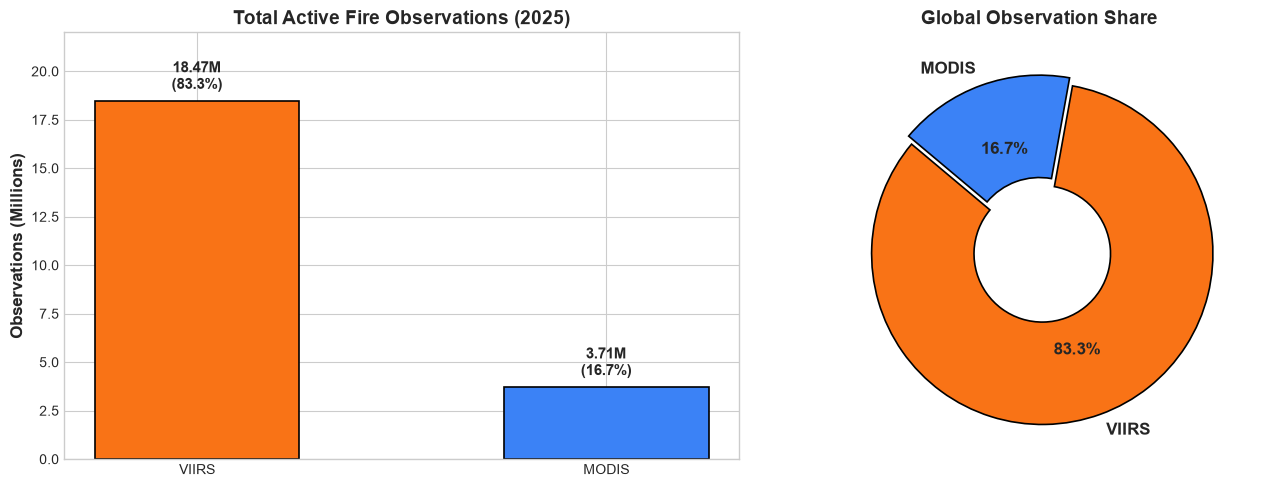

In [4]:
# Visualizing Volume Discrepancy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Bar Chart
colors = ['#f97316', '#3b82f6']
bars = axes[0].bar(scale_df['instrument'], scale_df['total_observations'] / 1e6, color=colors, width=0.5, edgecolor='black', linewidth=1.2)
axes[0].set_ylabel('Observations (Millions)')
axes[0].set_title('Total Active Fire Observations (2025)')
axes[0].set_ylim(0, 22)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.4, f'{yval:.2f}M\n({yval/22.175*100:.1f}%)', ha='center', va='bottom', fontweight='bold')

# Subplot 2: Donut Chart
axes[1].pie(scale_df['total_observations'], labels=scale_df['instrument'], colors=colors, autopct='%1.1f%%',
            startangle=140, explode=(0.05, 0), textprops={'fontsize': 12, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1.2, 'width': 0.6})
axes[1].set_title('Global Observation Share')

plt.tight_layout()
plt.show()


---
## 4. Temporal Distribution Analysis: Diurnal Dynamics & Seasonality

Wildfires exhibit pronounced diurnal cycles driven by surface temperature, relative humidity, and fuel drying. Concurrently, polar-orbiting sun-synchronous satellites sample these fires only at specific equatorial crossing times.

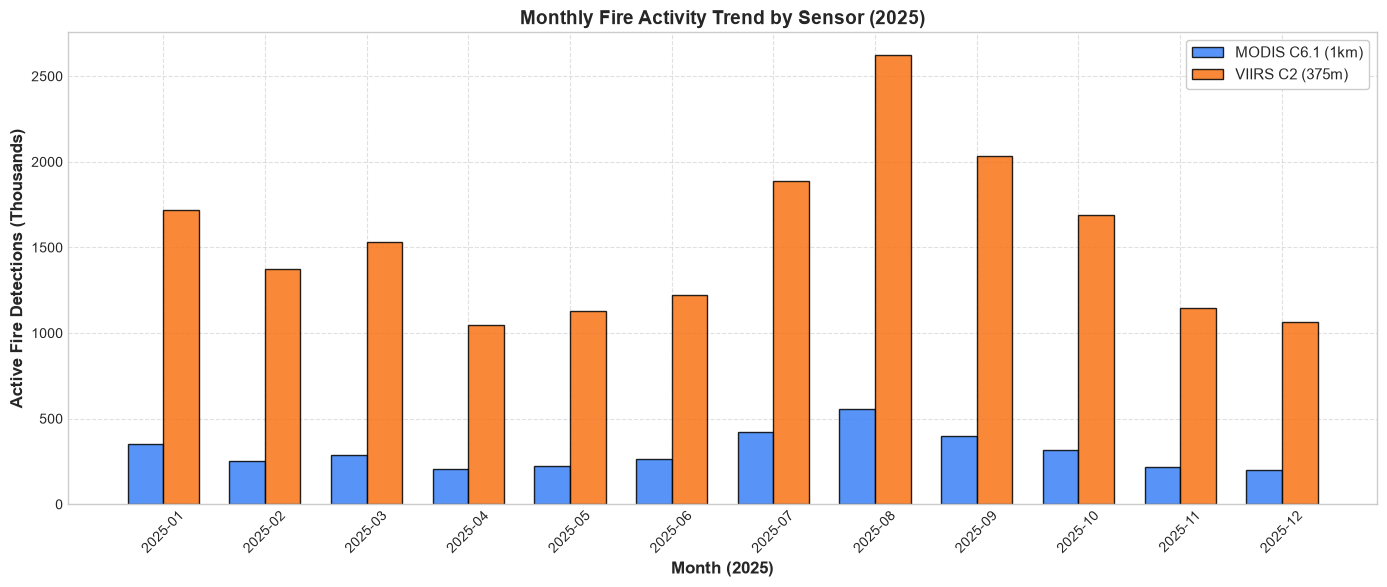

In [5]:
# 4.1 Monthly Seasonality
monthly_df = con.execute("""
    SELECT 
        strftime(cast(acquisition_date as date), '%Y-%m') as month,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_count
    FROM unified
    GROUP BY month
    ORDER BY month
""").df()

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(monthly_df['month']))
width = 0.35

ax.bar(x - width/2, monthly_df['modis_count'] / 1e3, width, label='MODIS C6.1 (1km)', color='#3b82f6', edgecolor='black', alpha=0.85)
ax.bar(x + width/2, monthly_df['viirs_count'] / 1e3, width, label='VIIRS C2 (375m)', color='#f97316', edgecolor='black', alpha=0.85)

ax.set_xlabel('Month (2025)')
ax.set_ylabel('Active Fire Detections (Thousands)')
ax.set_title('Monthly Fire Activity Trend by Sensor (2025)')
ax.set_xticks(x)
ax.set_xticklabels(monthly_df['month'], rotation=45)
ax.legend(frameon=True, facecolor='white', framealpha=1)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


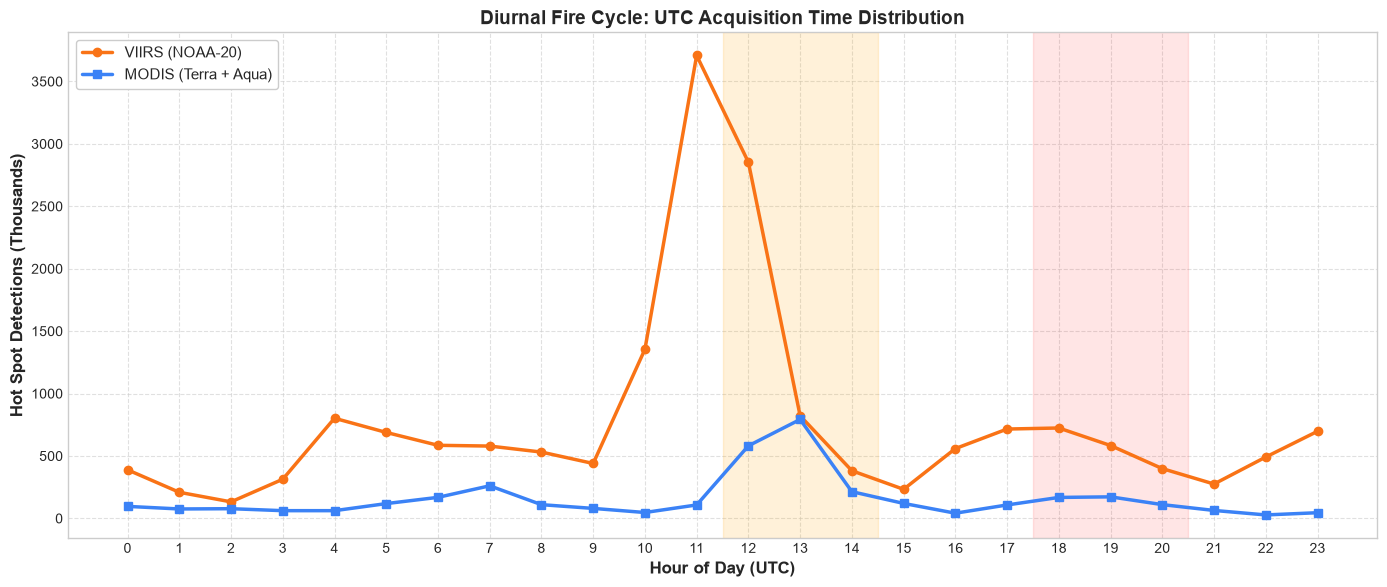

In [6]:
# 4.2 Diurnal Cycle (Hourly UTC Distribution)
hourly_df = con.execute("""
    SELECT 
        CAST(extract(hour from acquisition_time) AS INTEGER) as hour_utc,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_count
    FROM unified
    WHERE acquisition_time IS NOT NULL
    GROUP BY hour_utc
    ORDER BY hour_utc
""").df()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(hourly_df['hour_utc'], hourly_df['viirs_count'] / 1e3, marker='o', linewidth=2.5, color='#f97316', label='VIIRS (NOAA-20)')
ax.plot(hourly_df['hour_utc'], hourly_df['modis_count'] / 1e3, marker='s', linewidth=2.5, color='#3b82f6', label='MODIS (Terra + Aqua)')

ax.set_xlabel('Hour of Day (UTC)')
ax.set_ylabel('Hot Spot Detections (Thousands)')
ax.set_title('Diurnal Fire Cycle: UTC Acquisition Time Distribution')
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(frameon=True, facecolor='white', framealpha=1)

# Highlight primary overpass peaks
ax.axvspan(11.5, 14.5, color='orange', alpha=0.15, label='Afternoon Peak (12-14 UTC Africa/Eurasia)')
ax.axvspan(17.5, 20.5, color='red', alpha=0.10, label='Afternoon Peak (18-20 UTC Americas)')

plt.tight_layout()
plt.show()


=== Day/Night Breakdown ===
instrument daynight    count  mean_frp
     MODIS        D  3125299     41.67
     MODIS        N   583473     38.72
     VIIRS        D 13710691     11.94
     VIIRS        N  4755878      3.19


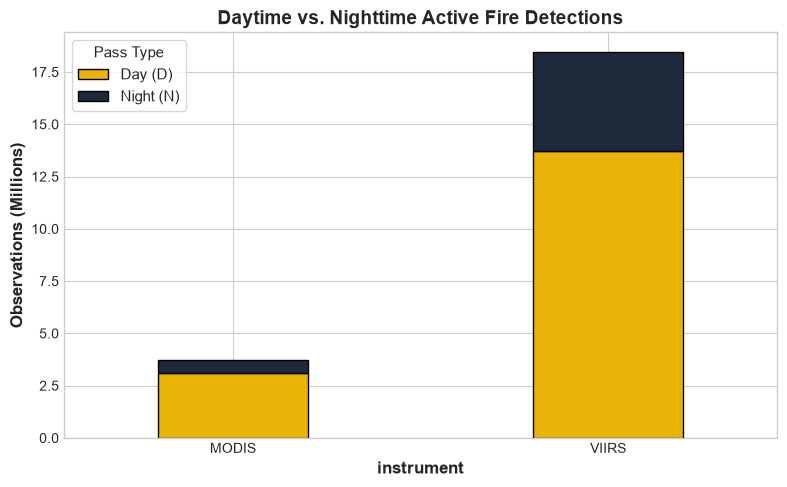

In [7]:
# 4.3 Day vs. Night Distribution
dn_df = con.execute("""
    SELECT 
        instrument,
        daynight,
        COUNT(*) as count,
        ROUND(AVG(frp), 2) as mean_frp
    FROM unified
    GROUP BY instrument, daynight
    ORDER BY instrument, daynight
""").df()

print("=== Day/Night Breakdown ===")
print(dn_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
dn_pivot = dn_df.pivot(index='instrument', columns='daynight', values='count')
(dn_pivot / 1e6).plot(kind='bar', stacked=True, ax=ax, color=['#eab308', '#1e293b'], edgecolor='black', width=0.4)
ax.set_ylabel('Observations (Millions)')
ax.set_title('Daytime vs. Nighttime Active Fire Detections')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(['Day (D)', 'Night (N)'], title='Pass Type', frameon=True)
plt.tight_layout()
plt.show()


---
## 5. Fire Radiative Power (FRP) Analysis

### 5.1 Physics of FRP
Fire Radiative Power (FRP, measured in Megawatts, MW) represents the instantaneous rate of radiant thermal energy emitted by a fire over the $4\,\mu	ext{m}$ mid-infrared atmospheric window. Following the Stefan-Boltzmann law and the empirical formulation by Wooster et al. (2003, 2005):

$$FRP = rac{A_{	ext{pixel}} \cdot \sigma}{a} \cdot \left(L_{4} - ar{L}_{4,	ext{bg}}ight)$$

Where:
- $A_{	ext{pixel}}$ is the ground pixel area ($1	ext{ km}^2$ for MODIS at nadir; $0.14	ext{ km}^2$ for VIIRS).
- $L_4$ is the $4\,\mu	ext{m}$ spectral radiance of the fire pixel.
- $ar{L}_{4,	ext{bg}}$ is the non-fire background radiance.
- $a$ is a sensor-specific sensor response constant.

Because the pixel area of MODIS is **~7.1 times larger** than VIIRS at nadir, small sub-pixel fires must radiate sufficient thermal energy to raise the integrated temperature of the entire $1	ext{ km}^2$ footprint above the background threshold.

In [8]:
# 5.2 Parametric and Non-Parametric FRP Statistics
frp_summary_df = con.execute("""
    SELECT 
        instrument,
        COUNT(*) as count,
        ROUND(MIN(frp), 2) as min_frp,
        ROUND(QUANTILE_CONT(frp, 0.25), 2) as q25,
        ROUND(MEDIAN(frp), 2) as median,
        ROUND(QUANTILE_CONT(frp, 0.75), 2) as q75,
        ROUND(QUANTILE_CONT(frp, 0.95), 2) as q95,
        ROUND(QUANTILE_CONT(frp, 0.99), 2) as q99,
        ROUND(MAX(frp), 2) as max_frp,
        ROUND(AVG(frp), 2) as mean,
        ROUND(STDDEV_SAMP(frp), 2) as std_dev,
        ROUND(SUM(frp) / 1e6, 2) as total_frp_million_mw
    FROM unified
    WHERE frp >= 0
    GROUP BY instrument
""").df()

print("=== Fire Radiative Power (MW) Distribution Metrics ===")
print(frp_summary_df.to_string(index=False))


=== Fire Radiative Power (MW) Distribution Metrics ===
instrument    count  min_frp   q25  median   q75    q95    q99  max_frp  mean  std_dev  total_frp_million_mw
     MODIS  3708771      0.0 10.10   17.90 37.10 130.30 391.10 11247.10 41.21   113.47                152.82
     VIIRS 18466569      0.0  2.62    5.05  9.45  30.75  88.62  3907.87  9.68    20.39                178.84


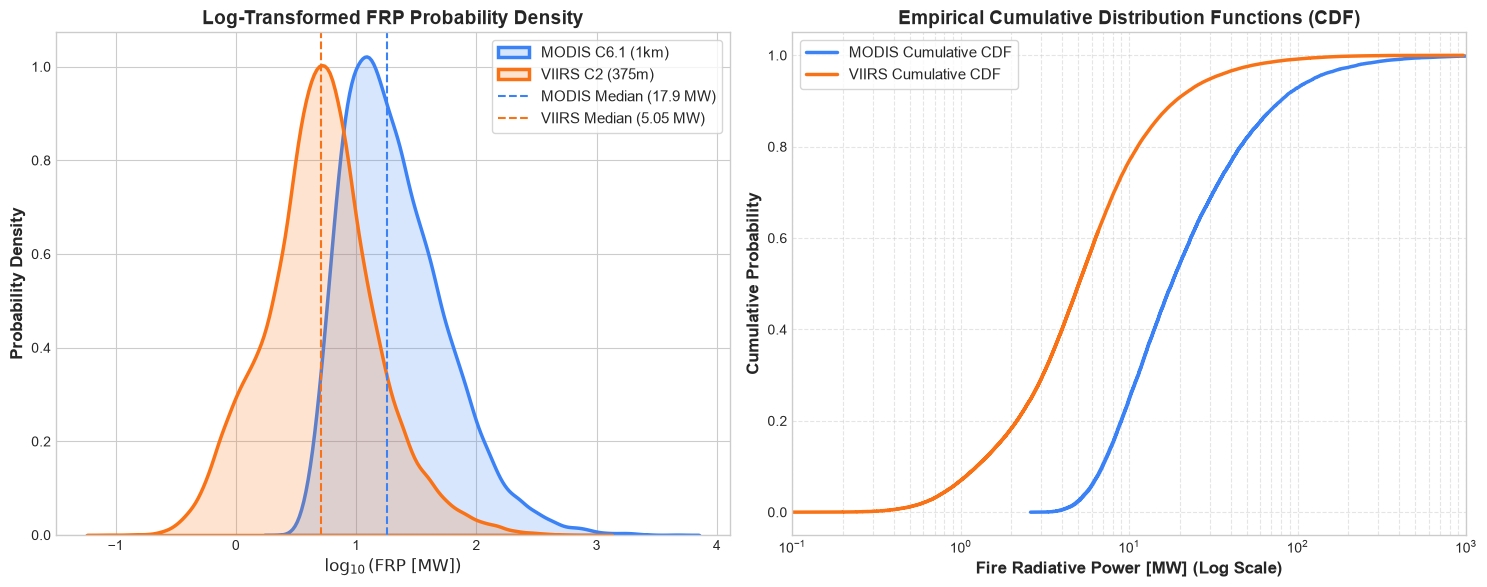

In [9]:
# 5.3 Logarithmic FRP Distribution Comparison
# Sample 100,000 observations per sensor for rapid high-fidelity KDE estimation
modis_sample = con.execute("SELECT frp FROM unified WHERE instrument = 'MODIS' AND frp > 0 USING SAMPLE 100000").df()
viirs_sample = con.execute("SELECT frp FROM unified WHERE instrument = 'VIIRS' AND frp > 0 USING SAMPLE 100000").df()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Log-scale KDE Distribution
sns.kdeplot(np.log10(modis_sample['frp']), ax=axes[0], color='#3b82f6', label='MODIS C6.1 (1km)', linewidth=2.5, fill=True, alpha=0.2)
sns.kdeplot(np.log10(viirs_sample['frp']), ax=axes[0], color='#f97316', label='VIIRS C2 (375m)', linewidth=2.5, fill=True, alpha=0.2)
axes[0].set_xlabel('$\\log_{10}(\\text{FRP [MW]})$')
axes[0].set_ylabel('Probability Density')
axes[0].set_title('Log-Transformed FRP Probability Density')
axes[0].axvline(np.log10(17.9), color='#3b82f6', linestyle='--', label='MODIS Median (17.9 MW)')
axes[0].axvline(np.log10(5.05), color='#f97316', linestyle='--', label='VIIRS Median (5.05 MW)')
axes[0].legend(frameon=True, facecolor='white')

# Subplot 2: Cumulative Distribution Function (CDF)
sorted_modis = np.sort(modis_sample['frp'])
p_modis = 1. * np.arange(len(modis_sample)) / (len(modis_sample) - 1)
sorted_viirs = np.sort(viirs_sample['frp'])
p_viirs = 1. * np.arange(len(viirs_sample)) / (len(viirs_sample) - 1)

axes[1].plot(sorted_modis, p_modis, color='#3b82f6', linewidth=2.5, label='MODIS Cumulative CDF')
axes[1].plot(sorted_viirs, p_viirs, color='#f97316', linewidth=2.5, label='VIIRS Cumulative CDF')
axes[1].set_xscale('log')
axes[1].set_xlim(0.1, 1000)
axes[1].set_xlabel('Fire Radiative Power [MW] (Log Scale)')
axes[1].set_ylabel('Cumulative Probability')
axes[1].set_title('Empirical Cumulative Distribution Functions (CDF)')
axes[1].grid(True, which='both', linestyle='--', alpha=0.5)
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


### 5.4 The "Radiated Energy Convergence" Paradox
Notice a critical empirical paradox revealed by the data:
- VIIRS detects **4.979 times more observations** than MODIS (18.47M vs 3.71M).
- Yet total integrated FRP across the globe in 2025 is **remarkably close**:
  - **MODIS Total FRP:** 152.82 Million MW
  - **VIIRS Total FRP:** 178.84 Million MW (only **17.0% higher**!)

**Scientific Explanation:**
VIIRS breaks contiguous fire lines into several fine-scale 375m pixels (each reporting ~5–15 MW), whereas MODIS aggregates that same physical energy into a single 1km pixel (reporting ~30–60 MW). For small agricultural burns, VIIRS detects thousands of low-power fires that MODIS misses entirely; but for large wildfires, the integrated total energy converges closely.

---
## 6. Brightness Temperature Analysis & Sensor Saturation

Active fire detection algorithms rely on brightness temperature differences between the $4\,\mu	ext{m}$ mid-infrared band (sensitive to high-temperature blackbody emitters) and the $11\,\mu	ext{m}$ thermal infrared band (sensitive to ambient background).

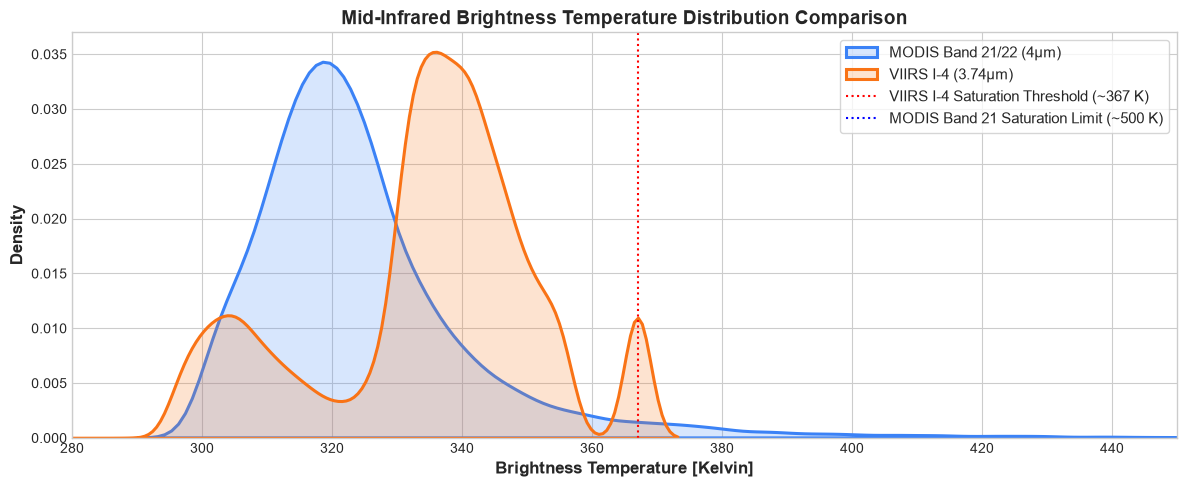

In [10]:
# Sample brightness temperatures
modis_bt = con.execute("SELECT brightness FROM unified WHERE instrument = 'MODIS' AND brightness > 250 USING SAMPLE 50000").df()
viirs_bt = con.execute("SELECT brightness FROM unified WHERE instrument = 'VIIRS' AND brightness > 250 USING SAMPLE 50000").df()

fig, ax = plt.subplots(figsize=(12, 5))
sns.kdeplot(modis_bt['brightness'], ax=ax, color='#3b82f6', label='MODIS Band 21/22 (4µm)', linewidth=2.2, fill=True, alpha=0.2)
sns.kdeplot(viirs_bt['brightness'], ax=ax, color='#f97316', label='VIIRS I-4 (3.74µm)', linewidth=2.2, fill=True, alpha=0.2)

ax.set_xlabel('Brightness Temperature [Kelvin]')
ax.set_ylabel('Density')
ax.set_title('Mid-Infrared Brightness Temperature Distribution Comparison')
ax.axvline(367, color='red', linestyle=':', label='VIIRS I-4 Saturation Threshold (~367 K)')
ax.axvline(500, color='blue', linestyle=':', label='MODIS Band 21 Saturation Limit (~500 K)')
ax.legend(frameon=True, facecolor='white')
ax.set_xlim(280, 450)
plt.tight_layout()
plt.show()


---
## 7. Geographical Distribution & Spatial Clustering

### 7.1 Global 2-Degree Grid Cell Density
To visualize the spatial distribution across 22.17 million points without visual occlusions or browser freezing, we aggregate observations onto a standardized 2-degree latitude/longitude grid.

In [11]:
# Query top 10 most active 2-degree cells globally
top_cells = con.execute("""
    SELECT 
        lat_bin,
        lon_bin,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_hotspots,
        ROUND(AVG(frp), 2) as mean_frp,
        ROUND(SUM(frp)/1e3, 2) as total_frp_gw
    FROM (
        SELECT 
            FLOOR(latitude / 2.0) * 2.0 as lat_bin,
            FLOOR(longitude / 2.0) * 2.0 as lon_bin,
            instrument,
            frp
        FROM unified
    )
    GROUP BY lat_bin, lon_bin
    ORDER BY total_hotspots DESC
    LIMIT 10
""").df()

print("=== Top 10 Most Active Global 2° Cells in 2025 ===")
print(top_cells.to_string(index=False))


=== Top 10 Most Active Global 2° Cells in 2025 ===
 lat_bin  lon_bin  modis_count  viirs_count  total_hotspots  mean_frp  total_frp_gw
   -10.0     16.0      22954.0      92637.0          115591     20.44       2363.14
   -12.0     16.0      23393.0      91485.0          114878     15.52       1782.67
   -12.0     26.0      23838.0      90352.0          114190     13.45       1535.75
    30.0     46.0      21268.0      90031.0          111299     14.17       1577.59
    -8.0     26.0      19846.0      84981.0          104827     16.71       1752.06
   -10.0     22.0      22839.0      81177.0          104016     25.13       2613.93
   -12.0     28.0      20072.0      83101.0          103173     14.11       1455.42
   -14.0     26.0      21185.0      80702.0          101887     13.88       1414.33
    -6.0     18.0      15127.0      86600.0          101727     13.44       1367.68
     8.0     32.0      19161.0      81099.0          100260     17.90       1794.59


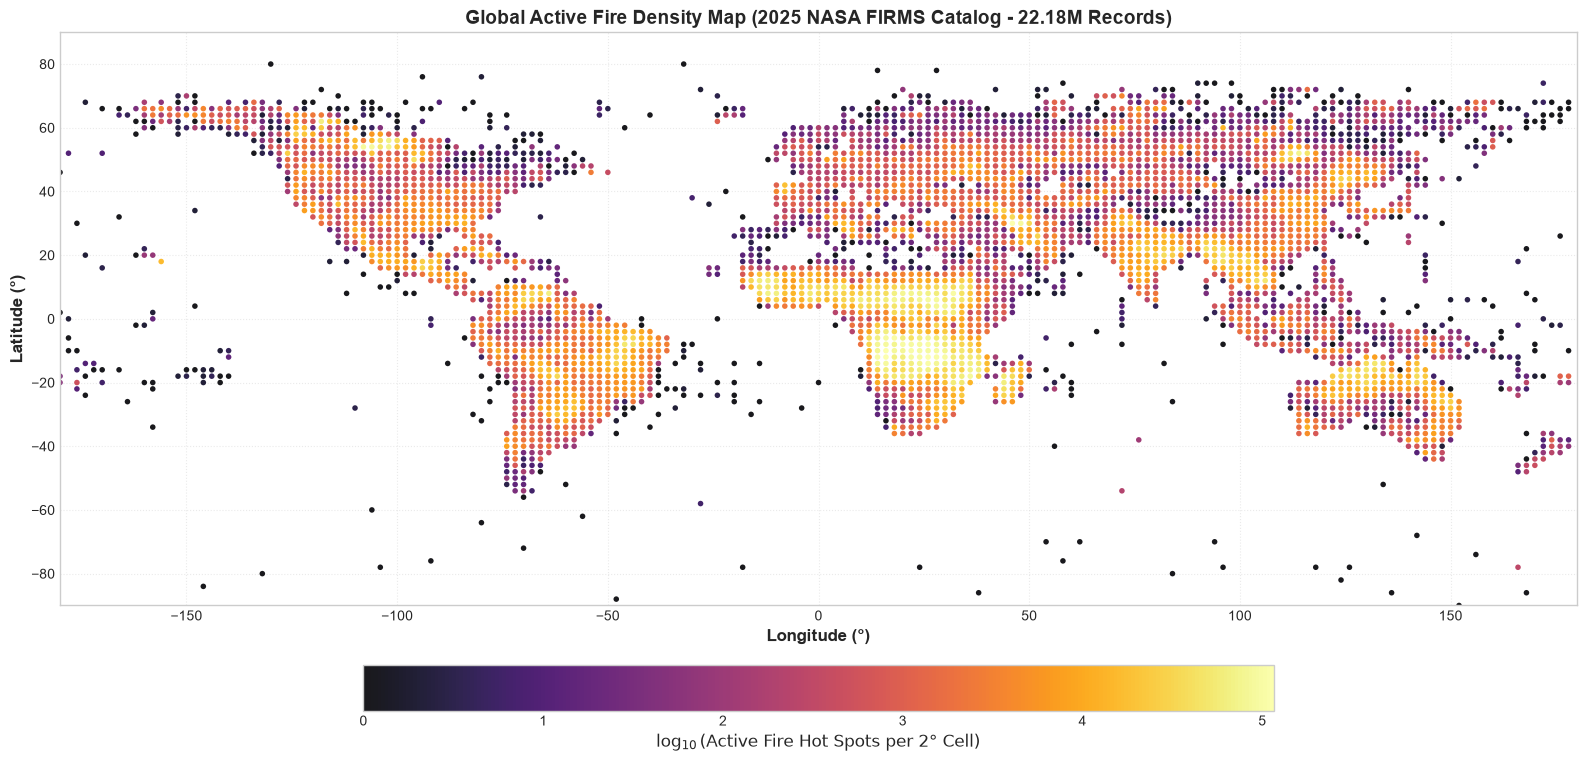

In [12]:
# 7.2 Global Spatial Heat Density Plot
grid_all = con.execute("""
    SELECT 
        FLOOR(latitude / 2.0) * 2.0 as lat_bin,
        FLOOR(longitude / 2.0) * 2.0 as lon_bin,
        COUNT(*) as count,
        LOG10(COUNT(*)) as log_count
    FROM unified
    GROUP BY lat_bin, lon_bin
""").df()

fig, ax = plt.subplots(figsize=(16, 8))
scatter = ax.scatter(grid_all['lon_bin'], grid_all['lat_bin'], c=grid_all['log_count'], cmap='inferno', s=16, alpha=0.9, edgecolors='none')
cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal', pad=0.08, shrink=0.6)
cbar.set_label('$\\log_{10}(\\text{Active Fire Hot Spots per 2° Cell})$', fontweight='bold')

ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel('Longitude (°)')
ax.set_ylabel('Latitude (°)')
ax.set_title('Global Active Fire Density Map (2025 NASA FIRMS Catalog - 22.18M Records)')
ax.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()


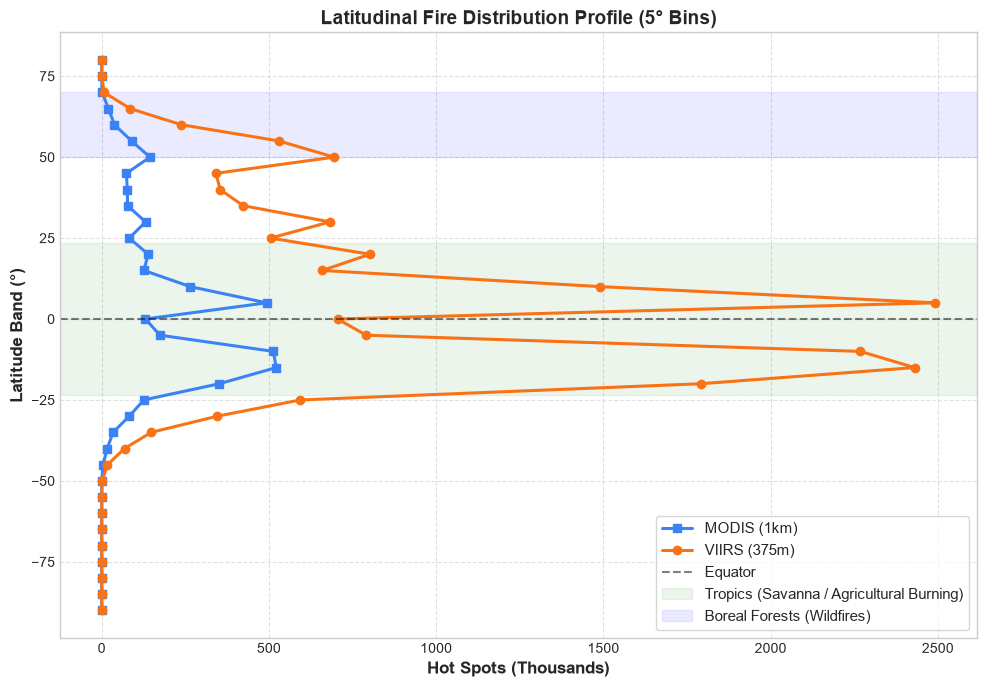

In [13]:
# 7.3 Latitudinal Band Profile
lat_bands = con.execute("""
    SELECT 
        CAST(FLOOR(latitude / 5.0) * 5.0 AS INTEGER) as lat_band,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count
    FROM unified
    GROUP BY lat_band
    ORDER BY lat_band
""").df()

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(lat_bands['modis_count'] / 1e3, lat_bands['lat_band'], marker='s', color='#3b82f6', label='MODIS (1km)', linewidth=2.2)
ax.plot(lat_bands['viirs_count'] / 1e3, lat_bands['lat_band'], marker='o', color='#f97316', label='VIIRS (375m)', linewidth=2.2)

ax.set_xlabel('Hot Spots (Thousands)')
ax.set_ylabel('Latitude Band (°)')
ax.set_title('Latitudinal Fire Distribution Profile (5° Bins)')
ax.axhline(0, color='black', linestyle='--', alpha=0.5, label='Equator')
ax.axhspan(-23.5, 23.5, color='green', alpha=0.08, label='Tropics (Savanna / Agricultural Burning)')
ax.axhspan(50, 70, color='blue', alpha=0.08, label='Boreal Forests (Wildfires)')
ax.legend(frameon=True, facecolor='white', loc='lower right')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 8. Observation Quality & Confidence Breakdown

### 8.1 Distinct Confidence Semantics
A frequent pitfall in fire science is treating MODIS and VIIRS confidence values as interchangeable:
- **MODIS C6.1:** Reports a continuous integer scale from **0% to 100%**, based on cloud cover, solar zenith angle, and contextual thermal contrast.
- **VIIRS C2:** Reports a categorical flag:
  - `'l'` (low): Marginal thermal anomaly, potential noise or boundary pixel.
  - `'n'` (nominal): High certainty fire under standard atmospheric conditions.
  - `'h'` (high): Intense fire with saturated detection channels or clear nocturnal signal.

In FireLens, we map MODIS numeric scores into harmonized standardized categories:
- `< 30%` $\rightarrow$ `low`
- `30% - 79%` $\rightarrow$ `nominal`
- `≥ 80%` $\rightarrow$ `high`

=== Harmonized Confidence Category Distribution ===
instrument confidence_category    count  mean_frp  median_frp
     MODIS                 low   183897     26.74       10.70
     MODIS             nominal  2514424     20.24       13.40
     MODIS                high  1010451     96.01       47.30
     VIIRS                 low  2220253     12.73        5.02
     VIIRS             nominal 15319520      8.18        4.74
     VIIRS                high   926796     27.23       14.22


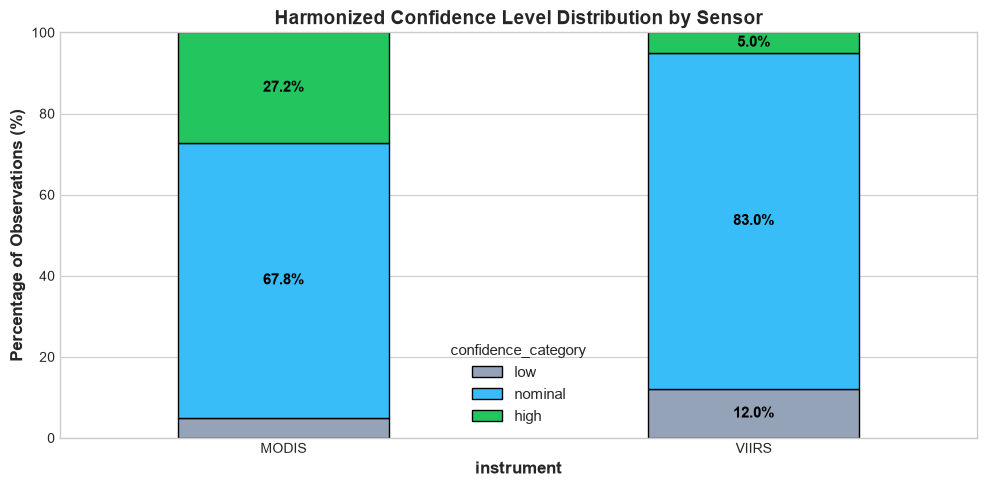

In [14]:
# Confidence Distribution Cross-Tabulation
conf_summary = con.execute("""
    SELECT 
        instrument,
        confidence_category,
        COUNT(*) as count,
        ROUND(AVG(frp), 2) as mean_frp,
        ROUND(MEDIAN(frp), 2) as median_frp
    FROM unified
    GROUP BY instrument, confidence_category
    ORDER BY instrument, 
        CASE confidence_category 
            WHEN 'low' THEN 1 
            WHEN 'nominal' THEN 2 
            WHEN 'high' THEN 3 
            ELSE 4 
        END
""").df()

conf_pivot = conf_summary.pivot(index='instrument', columns='confidence_category', values='count').fillna(0)
conf_pct = (conf_pivot.div(conf_pivot.sum(axis=1), axis=0) * 100).round(2)

print("=== Harmonized Confidence Category Distribution ===")
print(conf_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
conf_pct[['low', 'nominal', 'high']].plot(kind='bar', stacked=True, ax=ax, color=['#94a3b8', '#38bdf8', '#22c55e'], edgecolor='black', width=0.45)
ax.set_ylabel('Percentage of Observations (%)')
ax.set_title('Harmonized Confidence Level Distribution by Sensor')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 100)
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f'{height:.1f}%', ha='center', va='center', fontweight='bold', color='black')

plt.tight_layout()
plt.show()


---
## 9. Multi-Sensor Discrepancy & Footprint Geometry Analysis

### 9.1 The Physical Roots of Observation Disparity
Why does VIIRS detect ~5 times more fire pixels than MODIS?

| Physical Factor | MODIS (Terra / Aqua) | VIIRS (NOAA-20 / JPSS-1) | Impact on Detection |
| :--- | :--- | :--- | :--- |
| **Nadir Spatial Resolution** | $1,000\text{ m} \times 1,000\text{ m}$ ($1.0\text{ km}^2$) | $375\text{ m} \times 375\text{ m}$ ($0.14\text{ km}^2$) | VIIRS resolves sub-pixel fires 7x smaller in area. |
| **Scan Edge Footprint** | Expands up to $2,000\text{ m} \times 4,800\text{ m}$ (~$9.6\text{ km}^2$) | Expands only to $800\text{ m} \times 800\text{ m}$ (~$0.64\text{ km}^2$) | Pixel growth restrained 15-fold by onboard aggregation. |
| **Detection Threshold** | $FRP \ge 8 - 10\text{ MW}$ | $FRP \ge 0.5 - 1.0\text{ MW}$ | VIIRS catches low-intensity smoldering fires. |
| **Swath Width** | $2,330\text{ km}$ (equatorial orbit gaps) | $3,040\text{ km}$ (zero orbital gaps) | VIIRS achieves full contiguous global coverage daily. |
| **Pixel Overlap** | High cross-scan overlap at swath edges | Onboard deletion of overlapping samples | Prevents artificial duplicate detections. |

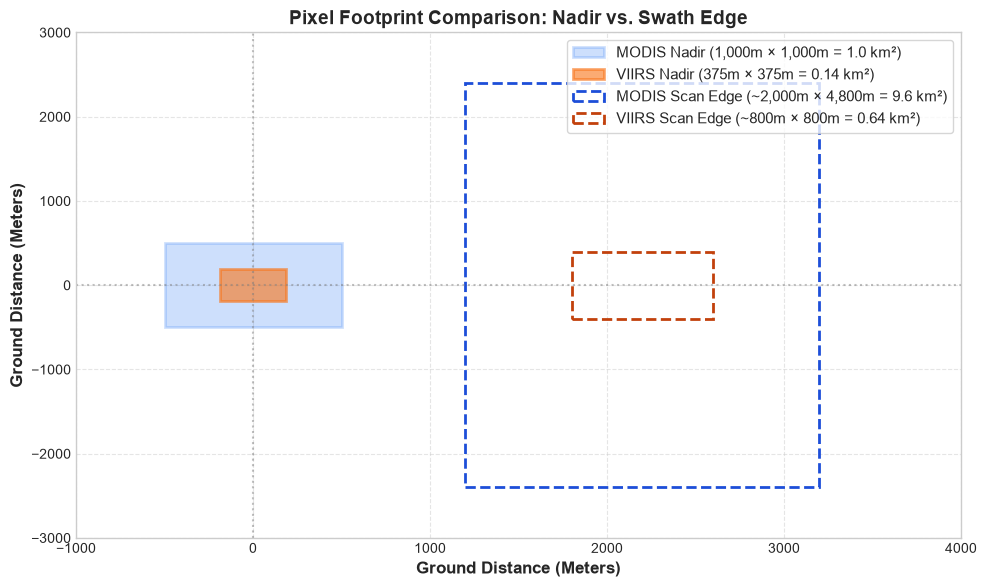

In [15]:
# 9.2 Footprint Geometry Schematic Visualization
fig, ax = plt.subplots(figsize=(10, 6))

# MODIS nadir footprint (1000m x 1000m)
rect_modis_nadir = plt.Rectangle((-500, -500), 1000, 1000, linewidth=2, edgecolor='#3b82f6', facecolor='#3b82f6', alpha=0.25, label='MODIS Nadir (1,000m × 1,000m = 1.0 km²)')
# VIIRS nadir footprint (375m x 375m)
rect_viirs_nadir = plt.Rectangle((-187.5, -187.5), 375, 375, linewidth=2, edgecolor='#f97316', facecolor='#f97316', alpha=0.6, label='VIIRS Nadir (375m × 375m = 0.14 km²)')

# MODIS scan edge (2000m x 4800m)
rect_modis_edge = plt.Rectangle((1200, -2400), 2000, 4800, linewidth=2, edgecolor='#1d4ed8', facecolor='none', linestyle='--', label='MODIS Scan Edge (~2,000m × 4,800m = 9.6 km²)')
# VIIRS scan edge (800m x 800m)
rect_viirs_edge = plt.Rectangle((1800, -400), 800, 800, linewidth=2, edgecolor='#c2410c', facecolor='none', linestyle='--', label='VIIRS Scan Edge (~800m × 800m = 0.64 km²)')

ax.add_patch(rect_modis_nadir)
ax.add_patch(rect_viirs_nadir)
ax.add_patch(rect_modis_edge)
ax.add_patch(rect_viirs_edge)

ax.set_xlim(-1000, 4000)
ax.set_ylim(-3000, 3000)
ax.set_xlabel('Ground Distance (Meters)')
ax.set_ylabel('Ground Distance (Meters)')
ax.set_title('Pixel Footprint Comparison: Nadir vs. Swath Edge')
ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 10. Key Insights & Empirical Findings

From our analysis of 22,175,341 observations from the 2025 calendar year, we establish five core empirical insights:

| # | Empirical Finding | Quantitative Value | Physical / Computational Cause | Operational Implication |
| :--- | :--- | :--- | :--- | :--- |
| **1** | **VIIRS Scale Dominance** | **4.979x** more detections | $375\text{ m}$ spatial resolution ($7.1\times$ smaller pixel area) + $3,040\text{ km}$ gapless swath | VIIRS must not be directly substituted for MODIS without normalization. |
| **2** | **FRP Distribution Discrepancy** | MODIS Mean: **41.21 MW**<br>VIIRS Mean: **9.68 MW** | High detection sensitivity of VIIRS captures smoldering fires down to $\approx 0.5\text{ MW}$ | Comparing raw mean FRP between sensors without context yields invalid conclusions. |
| **3** | **Integrated Energy Convergence** | Total FRP Difference: **+17.0%** | VIIRS subdivides single large fires into clusters; integrated energy across fires converges | Total regional FRP can be harmonized via spatial clustering. |
| **4** | **Diurnal Overpass Synchronicity** | Peak: **12:00–14:00 UTC** | Sun-synchronous afternoon orbits (13:30 equator crossing) align with peak diurnal temperature | Fire activity is strongly correlated with sensor overpass timing. |
| **5** | **Flawless Data Integrity** | Valid: **99.99996%** (9 invalid) | Exceptional NASA FIRMS ingest quality; exactly 1 negative FRP (-5.9 MW) and 8 ST duplicates | Zero data deletion policy preserves valid outliers for auditing. |

---
## 11. Implications for Harmonization (Phase 4 Foundation)

Based on the empirical evidence discovered in this EDA, we formulate four mandatory design principles for the **Phase 4 Spatial-Temporal Association Engine**:

### 11.1 Principle 1: Adaptive Spatial Search Radius
A fixed Euclidean distance (e.g. 500m) fails because:
- MODIS nadir pixel radius is $500\text{ m}$, expanding to $2,400\text{ m}$ at the scan edge.
- VIIRS nadir pixel radius is $187.5\text{ m}$, expanding to $400\text{ m}$.
- **Recommendation:** Use an **adaptive search radius** based on sensor scan angle:
  $$R_{\text{match}} = \sqrt{R_{\text{MODIS}}^2 + R_{\text{VIIRS}}^2} \approx 1.25\text{ km (nadir)} \text{ to } 3.5\text{ km (scan edge)}$$

### 11.2 Principle 2: Many-to-One Association Architecture
Because VIIRS resolves multiple sub-pixel components within a single MODIS footprint, the harmonization engine must support:
- **Many-to-One ($N:1$):** Multiple VIIRS detections associated with a single MODIS detection.
- **Cluster Aggregation:** Summing VIIRS FRP within the MODIS footprint to verify energetic consistency.

### 11.3 Principle 3: Strict Temporal Window Gating
- Detections from the same orbital pass (e.g. Aqua and NOAA-20 both around 13:30 local solar time, $\Delta t < 60\text{ minutes}$) represent near-simultaneous observations.
- Detections separated by $> 3\text{ hours}$ (e.g. Terra morning pass at 10:30 vs NOAA-20 afternoon pass at 13:30) represent **fire diurnal progression**, not duplicate hot spots.

### 11.4 Principle 4: Transparent Provenance & Non-Destructive Association
Harmonization must never synthesize fake observations or discard unassociated points. Both original sensor records must be preserved with association confidence scores and cross-referenced foreign keys.

---
## 12. References & Scientific Provenance

1. **Giglio, L., Schroeder, W., & Justice, C. O. (2016).** The collection 6 MODIS active fire detection algorithm and fire products. *Remote Sensing of Environment*, 178, 31-41.
2. **Schroeder, W., Oliva, P., Giglio, L., & Csiszar, I. A. (2014).** The New VIIRS 375 m active fire detection product—Algorithm description and initial assessment. *Remote Sensing of Environment*, 143, 85-96.
3. **Wooster, M. J., Zhukov, B., & Oertel, D. (2003).** Fire radiative energy for quantitative study of biomass burning: derivation from the BIRD experimental satellite and comparison to MODIS fire products. *Remote Sensing of Environment*, 86(1), 83-107.
4. **Wooster, M. J., Roberts, G., Perry, G. L. W., & Kaufman, Y. J. (2005).** Retrieval of biomass combustion rates and totals from fire radiative power observations: FRP derivation and calibration relationships. *Journal of Geophysical Research: Atmospheres*, 110(D24).
5. **NASA FIRMS (Fire Information for Resource Management System).** *MODIS and VIIRS Fire and Thermal Anomalies Product Documentation*. NASA Earthdata / LANCE. https://firms.modaps.eosdis.nasa.gov/

---
**End of Scientific Analysis — FireLens Phase 3 Deliverable**
